In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
from torch.utils.data import random_split, DataLoader, TensorDataset
from sklearn.metrics import accuracy_score
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import SGD, Adam


In [3]:
pip install ipywidgets 

Defaulting to user installation because normal site-packages is not writeable
     ------------------------------------- 139.8/139.8 kB 30.0 kB/s eta 0:00:00
     ------------------------------------- 216.6/216.6 kB 16.3 kB/s eta 0:00:00
     ---------------------------------------- 2.2/2.2 MB 32.5 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
# For reproducibility. Do not change the code in this cell.
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)
torch.manual_seed(42)

# Part A

## Load and preprocess the dataset


In [3]:
def data_prep(raw):
    num_images = raw.shape[0]
    x_as_array = raw.values[:,1:]
    out_y = raw.values[:, 0]
    x_shaped_array = x_as_array.reshape(num_images, 28, 28)
    out_x = x_shaped_array
    return out_x, out_y

# Make sure that the CSV files are in the same directory as this notebook file
raw_train = pd.read_csv("./fashion-mnist_train.csv")
raw_test = pd.read_csv("./fashion-mnist_test.csv")

In [4]:
x_train, y_train = data_prep(raw_train) 
x_test, y_test = data_prep(raw_test) 

In [14]:

# TODO: Normalize the dataset in the range [0, 1]
# Hint: In the dataset, the min RGB value is 0 and max is 255. How can you bring it in the range of [0, 1]?
# Recall broadcasting, which performs a mathematical operation on the whole dataset with a scalar.
x_train, x_test = ?, ?  

# TODO: Flatten the images
x_train, x_test = ?, ?  

# TODO: Convert the class labels to one-hot vectors
y_train_cat = to_categorical(y_train , 0)
y_test_cat = to_categorical(y_test , 0)

After implementing and running the above cell, you can continue from the next section if you want to work with TensorFlow. Otherwise, go to the PyTorch section if you want to work with PyTorch.

## TensorFlow

### Define the model

In [ ]:
# TODO: Write code to create an MLP architecture according to the specifications mentioned in the question paper
model = ?

### Compile the model

In [17]:
# TODO: Use the optimizer with learning rate specified in the question paper
optimizer = SGD(lr = 0.0001)

# TODO: Compile the model with either of the optimizers (SGD, Adam), categorical_crossentropy loss, and accuracy as metric to monitor
# YOUR CODE HERE


### Train the model


In [ ]:
# TODO: Fit the model with validation split as 20%. Make sure that you follow the batch_size and epochs as mentioned in the paper
# Note that ideally, it should take less than 5 minutes to train the model.
history = ?

### Plot training history

In [ ]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

# TODO: Extract loss and val_loss from the history dictionary
plt.plot(history.?, label='Train Loss')
plt.plot(history.?, label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss over Epochs')
plt.legend()

plt.subplot(1, 2, 2)

# TODO: Extract accuracy and val_accuracy from the history dictionary
plt.plot(history.?, label='Train Acc')
plt.plot(history.?, label='Val Acc')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy over Epochs')
plt.legend()

plt.show()

### Evaluate the model

In [ ]:
# TODO: Call the model's evaluate function on test split
_, test_acc = ?
print(f"\nTest Accuracy: {test_acc:.4f}")

### Predictions

In [ ]:
# TODO: Call the model's predict function on test split
y_pred = ?

# TODO: Print the first 10 predictions by getting the index with highest probability
# Hint: Refer to the cheat sheet
y_pred_labels = ?

print(f"Predicted labels: {y_pred_labels}")
print(f"Actual labels: {y_test}")

Example output:
```python
Predicted labels: array([9, 2, 1, 1, 6, 1, 4, 2, 7, 7])
Actual labels: array([9, 2, 1, 1, 6, 1, 4, 6, 5, 7])
```

## PyTorch

### PyTorch Cheat Sheet

```python
# Calculate accuracy
accuracy_score(true_labels, predicted_labels)

# PyTorch fully connected layer
nn.Linear(in_shape, out_shape)

# PyTorch activation functions
nn.Sigmoid()
nn.Softmax()
nn.Tanh()
nn.LeakyRelu()

# Creating a model archirecture in PyTorch
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.model = nn.Sequential(
            # Layers and activation functions goes here.
        )

    def forward(self, x):
        return self.model(x)


model = MLP()

# Optimizer and loss functions in PyTorch
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), learning_rate)

# Extracting the index with the highest value along the second dimension
torch.max(tensor, axis=1)

# PyTorch paradigm for inference
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.numpy())
        all_labels.extend(labels.numpy())

``` 

### Prepare dataset for PyTorch model

In [5]:
x_train = torch.tensor(x_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)

x_test = torch.tensor(x_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

In [6]:
# Define dataset
full_train_dataset = TensorDataset(x_train, y_train)
test_dataset = torch.utils.data.TensorDataset(x_test, y_test)

# Split into train and validation datasets (e.g., 80% train, 20% val)
# TODO: Replace the ? such that the train_size contains 80% and val_size contains 20% of the training split
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# Create DataLoaders with shuffling for both train and val
# TODO: Replace the ? with batch_size mentioned in question paper
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=True)

# Test loader remains the same
test_loader = DataLoader(test_dataset, batch_size=64)

### Define the model 

In [7]:

# Creating a model archirecture in PyTorch
class MLP(nn.Module):
    def __init__(self,l1 , h1 ,h2 ,h3 ,h4 ,h5 ,out):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(l1 , h1) # Layers and activation functions goes here
        self.fc2 = nn.Linear(h1 , h2 )
        self.fc3 = nn.Linear(h2 , h3 )
        self.fc4 = nn.Linear(h3 , h4 )
        self.fc5 = nn.Linear(h4 , h5 )
        self.fc6 = nn.Linear(h5 , out)


    def forward(self, x):
        x = nn.LeakyRelu(self.fc1(x))
        x = nn.LeakyRelu(self.fc2(x))
        x = nn.LeakyRelu(self.fc3(x))
        x = nn.Tanh(self.fc4(x))
        x = nn.Tanh(self.fc5(x))
        x = nn.Softmax(self.fc6(x))
        return self.model(x)

    
    
put = 784
h1 = 256
h2 = 128
h3 = 64
h4 = 32
h5 = 16
out = len(np.unique(y_train))
print(out)

10


### Prepare the model

In [8]:
# TODO: Use the optimizer with learning rate specified in the question paper
# Optimizer and loss functions in PyTorch
model = MLP(784 , 256 ,128 ,64 ,32 ,16 , 10)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(),0.0001)
# TODO: Set the CrossEntropyLoss for PyTorch
# YOUR CODE HERE

### Train the model

In [13]:

# PyTorch paradigm for inference
model.eval()
all_preds = []
all_labels = []



#with torch.no_grad():
    #for inputs, labels in test_loader:
        #outputs = model(inputs)
        #_, predicted = torch.max(outputs, 1)
        #all_preds.extend(predicted.numpy())
        #all_labels.extend(labels.numpy())
        
        
        
        
    # Validation Split
val_running_loss = 0
val_correct = 0
val_total = 0
with torch.no_grad():
    for val_inputs, val_labels in val_loader:
        val_outputs =  model(val_inputs) # TODO: Perform forward pass on current validation batch
        val_loss = 1 # TODO: Calculate loss on current validation batch

        val_running_loss += val_loss.item()
        _, predicted = torch.max(tensor, axis=1)  # TODO: Get the predicted labels for current validation batch by getting the index with highest probabilities
        val_total += val_labels.size(0)
        val_correct += (predicted == val_labels).sum().item()

val_epoch_loss = val_running_loss / len(val_loader)
val_epoch_acc = val_correct / val_total
val_losses.append(val_epoch_loss)
val_accuracies.append(val_epoch_acc)

print(
    f"Epoch {epoch+1}/{num_epochs} | "
    f"Train Loss: {train_losses[-1]:.4f}, Train Acc: {train_accuracies[-1]:.4f} | "
    f"Val Loss: {val_losses[-1]:.4f}, Val Acc: {val_accuracies[-1]:.4f}"
)
# Calculate accuracy
AAA = accuracy_score(val_correct, predicted)


AttributeError: module 'torch.nn' has no attribute 'LeakyRelu'

# Don't know why but it keeps giving me error module 'torch.nn' has no attribute 'LeakyRelu' I even tried with Torch still same error and with out this initial Training I can't move Forward T_T :'( 

In [12]:

# PyTorch paradigm for inference
model.eval()
all_preds = []
all_labels = []
# Validation Split
val_running_loss = 0
val_correct = 0
val_total = 0
with torch.no_grad():
    for val_inputs, val_labels in val_loader:
         val_outputs =  model(val_inputs) # TODO: Perform forward pass on current validation batch
        val_loss = 1 # TODO: Calculate loss on current validation batch
            val_running_loss += val_loss.item()
            _, predicted = torch.max(tensor, axis=1)  # TODO: Get the predicted labels for current validation batch by getting the index with highest probabilities
            val_total += val_labels.size(0)
            val_correct += (predicted == val_labels).sum().item()

    val_epoch_loss = val_running_loss / len(val_loader)
    val_epoch_acc = val_correct / val_total
    val_losses.append(val_epoch_loss)
    val_accuracies.append(val_epoch_acc)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_losses[-1]:.4f}, Train Acc: {train_accuracies[-1]:.4f} | "
        f"Val Loss: {val_losses[-1]:.4f}, Val Acc: {val_accuracies[-1]:.4f}"
    )
    # Calculate accuracy
accuracy_score(val_inputs, predicted)


IndentationError: unexpected indent (2301770960.py, line 9)

### Plot training history

NameError: name 'val_loss' is not defined

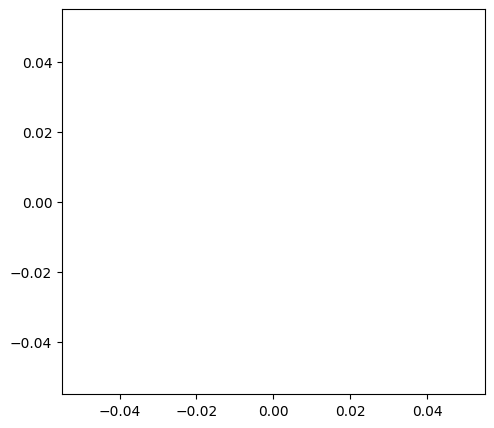

In [135]:
plt.figure(figsize=(12, 5))

# Loss plot
plt.subplot(1, 2, 1)

# TODO: Replace the ? with training and validation losses
plt.plot(train_losses, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss over Epochs')
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)

# TODO: Replace the ? with training and validation accuracies
plt.plot(accuracy_score, label='Train Accuracy')
plt.plot(val_accuracies, label='Val Accuracy', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy over Epochs')
plt.legend()

plt.show()

### Evaluate the model

In [136]:
# TODO: Evaluate the PyTorch model on test split
# Hint: Refer to the PyTorch cheat sheet
test_acc = accuracy_score(?, ?)
print(f"\nTest Accuracy: {test_acc:.4f}")

SyntaxError: invalid syntax (2569465979.py, line 3)

### Predictions

In [137]:
# TODO: Print the first 10 predictions
print(f"Predicted labels: {np.array(all_preds)}")
print(f"Actual labels: {y_test}")

Predicted labels: []
Actual labels: [0 1 2 ... 8 8 1]


Example Output

```python
Predicted labels: [1 1 1 1 1 1 1 1 1 1]
Actual labels: tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7])
```

# Part B

In [ ]:
# TODO: Reinitialize the mode and try different hyperparameters to meet the requirements mentioned in the paper
# YOUR CODE HERE

In [139]:
# TODO: Copy the code from Part A to fit the model
x_train = torch.tensor(x_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)

x_test = torch.tensor(x_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

C:\Users\Lab\AppData\Local\Temp\ipykernel_11872\1490126820.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_train = torch.tensor(x_train, dtype=torch.float32)
C:\Users\Lab\AppData\Local\Temp\ipykernel_11872\1490126820.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_train = torch.tensor(y_train, dtype=torch.long)
C:\Users\Lab\AppData\Local\Temp\ipykernel_11872\1490126820.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_test = torch.tensor(x_test, dtype=torch.float32)
C:\Users\Lab\AppData\Local\Temp\ipykernel_11872\149012682

In [140]:
# Define dataset
full_train_dataset = TensorDataset(x_train, y_train)
test_dataset = torch.utils.data.TensorDataset(x_test, y_test)

# Split into train and validation datasets (e.g., 80% train, 20% val)
# TODO: Replace the ? such that the train_size contains 80% and val_size contains 20% of the training split
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# Create DataLoaders with shuffling for both train and val
# TODO: Replace the ? with batch_size mentioned in question paper
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=True)

# Test loader remains the same
test_loader = DataLoader(test_dataset, batch_size=64)

In [141]:

# Creating a model archirecture in PyTorch
class MLP(nn.Module):
    def __init__(self,l1 , h1 ,h2 ,h3 ,h4 ,h5 ,out):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(l1 , h1) # Layers and activation functions goes here
        self.fc2 = nn.Linear(h1 , h2 )
        self.fc3 = nn.Linear(h2 , h3 )
        self.fc4 = nn.Linear(h3 , h4 )
        self.fc5 = nn.Linear(h4 , h5 )
        self.fc6 = nn.Linear(h5 , out)


    def forward(self, x):
        x = nn.LeakyRelu(self.fc1(x))
        x = nn.LeakyRelu(self.fc2(x))
        x = nn.LeakyRelu(self.fc3(x))
        x = nn.Tanh(self.fc4(x))
        x = nn.Tanh(self.fc5(x))
        x = nn.Softmax(self.fc6(x))
        return self.model(x)

    
    
put = 784
h1 = 256
h2 = 128
h3 = 64
h4 = 32
h5 = 16
out = len(np.unique(y_train))
print(out)

10


In [142]:
# TODO: Use the optimizer with learning rate specified in the question paper
# Optimizer and loss functions in PyTorch
model = MLP(784 , 256 ,128 ,64 ,32 ,16 , 10)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(),0.0001)
# TODO: Set the CrossEntropyLoss for PyTorch
# YOUR CODE HERE

In [143]:
# TODO: Fit the model. Make sure that you follow epochs as mentioned in the paper.
# Note that ideally, it should take less than 5 minutes to train the model.

num_epochs = 50

# Track training and validation metrics
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []



for epoch in range(num_epochs):
    
    # Train Split
    model.train()
    train_running_loss = 0
    train_correct = 0
    train_total = 0

    for train_inputs, train_labels in train_loader:
        train_outputs = model(x_train) # TODO: Perform forward pass on current training batch
        train_loss = criterion(output,y_train) # TODO: Calculate loss on current training batch

        # TODO: Zero the gradients
        optimizer.zero_grad()
        # TODO: Backpropagate the loss
        loss.backword()
        # TODO: Update the model parameters
        optimizer.step()

        train_running_loss += train_loss.item()
        _, predicted = torch.max(tensor, axis=1) # TODO: Get the predicted labels for current training batch by getting the index with highest probabilities
        train_total += train_labels.size(0)
        train_correct += (predicted == train_labels).sum().item()
        epoch_loss = train_running_loss / len(train_loader)
        epoch_acc = train_correct / train_total
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_acc)
 

AttributeError: module 'torch.nn' has no attribute 'LeakyRelu'

In [144]:

# PyTorch paradigm for inference
model.eval()
all_preds = []
all_labels = []



#with torch.no_grad():
    #for inputs, labels in test_loader:
        #outputs = model(inputs)
        #_, predicted = torch.max(outputs, 1)
        #all_preds.extend(predicted.numpy())
        #all_labels.extend(labels.numpy())
        
        
        
        
    # Validation Split
val_running_loss = 0
val_correct = 0
val_total = 0
with torch.no_grad():
    for val_inputs, val_labels in val_loader:
        val_outputs =  model(val_inputs) # TODO: Perform forward pass on current validation batch
        val_loss = 1 # TODO: Calculate loss on current validation batch

        val_running_loss += val_loss.item()
        _, predicted = torch.max(tensor, axis=1)  # TODO: Get the predicted labels for current validation batch by getting the index with highest probabilities
        val_total += val_labels.size(0)
        val_correct += (predicted == val_labels).sum().item()

val_epoch_loss = val_running_loss / len(val_loader)
val_epoch_acc = val_correct / val_total
val_losses.append(val_epoch_loss)
val_accuracies.append(val_epoch_acc)

print(
    f"Epoch {epoch+1}/{num_epochs} | "
    f"Train Loss: {train_losses[-1]:.4f}, Train Acc: {train_accuracies[-1]:.4f} | "
    f"Val Loss: {val_losses[-1]:.4f}, Val Acc: {val_accuracies[-1]:.4f}"
)
# Calculate accuracy
AAA = accuracy_score(val_correct, predicted)


AttributeError: module 'torch.nn' has no attribute 'LeakyRelu'

NameError: name 'val_loss' is not defined

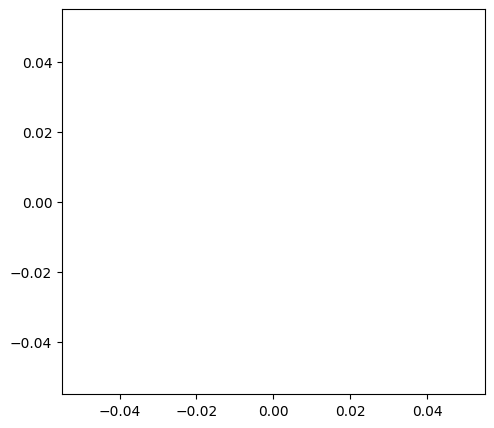

In [145]:
plt.figure(figsize=(12, 5))

# Loss plot
plt.subplot(1, 2, 1)

# TODO: Replace the ? with training and validation losses
plt.plot(train_losses, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss over Epochs')
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)

# TODO: Replace the ? with training and validation accuracies
plt.plot(AAA, label='Train Accuracy')
plt.plot(val_accuracies, label='Val Accuracy', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy over Epochs')
plt.legend()

plt.show()

In [ ]:
# TODO: Evaluate the PyTorch model on test split
# Hint: Refer to the PyTorch cheat sheet
  # Calculate accuracy
accuracy_score(val_correct, predicted)
print(f"\nTest Accuracy: {test_acc:.4f}")

In [ ]:
# TODO: Copy the plotting code from Part A
# TODO: Print the first 10 predictions
print(f"Predicted labels: {np.array(all_preds)}")
print(f"Actual labels: {y_test}")

# Observations

Write your observations in the following markdown cell.

 My Observation till NOw is That I have made an error some where in the code and now I am too Frustated to think of something else and have been stuck at the same error for the past hour and a half. But I think that by tuning the hypermeter tuning Would have for sured increase the accuracy of the model along with that increasing the number of parameters and decreasing the weights might also help a bit